# Week 9a.2: Deep Agents: The `deepagents` Library

In the previous notebook, we built a harness by hand: a to-do list, files in the graph state, and a `task` tool that runs a subagent with a fresh context. LangChain's `deepagents` library packages the same pieces, along with several more that we'll cover later in the course.

`create_deep_agent` is built on `create_agent` and its middleware, so this notebook is one of the places where we use a prebuilt agent instead of wiring the loop by hand. We'll open it up as we go, so that you can match each part of it to the code you wrote.

Documentation: https://docs.langchain.com/oss/python/deepagents/overview

The library is a separate package. Install it in your project folder with

```
uv pip install deepagents
```

In [1]:
from dotenv import load_dotenv
import os

load_dotenv()
assert os.getenv("GOOGLE_API_KEY"), "No GOOGLE_API_KEY found."
print("API key loaded")

API key loaded


## 0. Model Setup

Execute one of the following to define the model.

In [ ]:
from langchain_ollama import ChatOllama

model = ChatOllama(model="qwen3.5:9b", reasoning=False)

In [ ]:
from langchain.chat_models import init_chat_model

model = init_chat_model(model="gpt-4.1-mini")

In [2]:
from langchain.chat_models import init_chat_model

model = init_chat_model(model="claude-haiku-5-5")

In [ ]:
from langchain_google_genai import ChatGoogleGenerativeAI

model = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

## 1. The same task

We'll use the same three-part literature review and the same paper tools as in W09a.1.

In [3]:
import time
from langchain.messages import HumanMessage

import research_tools as rt
import research_team as team

qs = list(rt.questions())
parts = [qs[3], qs[2], qs[4]]
QUESTION = "Write a short literature review for a newcomer on three questions. " + " ".join(parts)
GOLD = sorted(set(g for q in parts for g in rt.questions()[q]["gold"]))

## 2. A deep agent

`create_deep_agent` takes a model, a system prompt, and a list of subagents. 

Each subagent is a dictionary with a name, a description, a prompt, and its tools.

- The **description** is what the lead reads when it decides whom to delegate to, so it is written for the lead, the same way a tool's docstring is written for the model.
- The **prompt** is the subagent's system prompt. It is the same researcher prompt as in W09a.1.

The to-do list is not on by default in the current version of the library. `TodoListMiddleware` adds the `write_todos` tool.

In [4]:
from deepagents import create_deep_agent
from langchain.agents.middleware import TodoListMiddleware
from langgraph.checkpoint.memory import InMemorySaver

RESEARCHER_PROMPT = """You are a research assistant. You get one piece of research to do, and the
instructions are all you know about the larger task.
Search with search_papers, read the two to four papers that matter with get_paper, and save your notes
with write_file at the path the instructions give, with every claim followed by the paper id in brackets
like [2503.13657].
Then reply with a summary of at most 80 words that names the file and the paper ids you cited.
Cite only papers you have read."""

LEAD_PROMPT = """You are the lead of a research team. Start with a to-do list. Delegate the literature
searches to the researcher subagent with the task tool, one call per part of the question, and give each
its own notes file under /notes/.
Read the notes you need, then write the report to /report.md: what is known, organized by the parts of
the question, every claim followed by the paper id in brackets as the notes give it.
When /report.md is written, reply with one sentence saying so."""

researcher = {
    "name": "researcher",
    "description": "Searches the literature on one part of a question, saves notes to a file, "
                   "and returns a short summary with paper ids.",
    "system_prompt": RESEARCHER_PROMPT,
    "tools": [rt.search_papers, rt.get_paper],
}


In [9]:
agent = create_deep_agent(
    model=model,
    system_prompt=LEAD_PROMPT,
    checkpointer=InMemorySaver(),
    middleware=[TodoListMiddleware()],
    subagents=[researcher]
    )

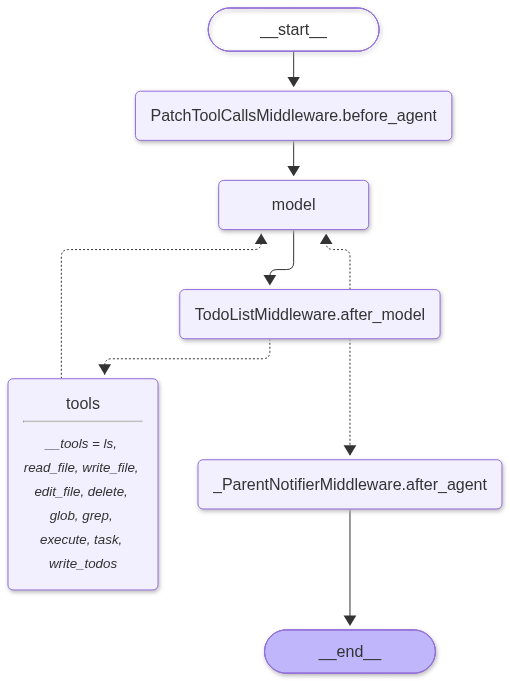

In [10]:
from IPython.display import Image, display
display(Image(agent.get_graph().draw_mermaid_png()))

### What the lead can call

Let's list the tools the lead's model is given. We did not pass any tools to `create_deep_agent`, so all of these come from the library.

In [11]:
lead_tools = agent.nodes["tools"].bound.tools_by_name
list(lead_tools)

['ls',
 'read_file',
 'write_file',
 'edit_file',
 'delete',
 'glob',
 'grep',
 'execute',
 'task',
 'write_todos']

- By default the files live in the graph state, as ours did.
- `ls`, `read_file`, `write_file`, `edit_file`, `delete`, `glob`, and `grep` work on the agent's files. 
- `write_todos` is the to-do list.
- `task` creates a subagent.
- `execute` runs shell commands. Without a sandbox, it returns an error. We'll give it a sandbox on Friday.

The `task` tool's description tells the lead how to delegate:

In [12]:
print(lead_tools["task"].description)

Launch an ephemeral subagent to handle a complex, multi-step task.

Available agent types and the tools they have access to:
- general-purpose: General-purpose agent for researching complex questions, searching for files and content, and executing multi-step tasks. When you are searching for a keyword or file and are not confident that you will find the right match in the first few tries use this agent to perform the search for you. This agent has access to all tools as the main agent.
- researcher: Searches the literature on one part of a question, saves notes to a file, and returns a short summary with paper ids.

Specify subagent_type to select the agent. Usage notes:
- Launch multiple agents concurrently when their tasks are independent, using a single message with multiple tool calls.
- Each invocation is stateless by default: the agent sees only the prompt you give it and returns a single final report. Put full detail in the prompt and state exactly what it should return — unless

NOTE:

The library also adds a `general-purpose` subagent, which has the same tools as the lead. We'll ask the lead to use `researcher`, but it is allowed to pick either one.

## 3. Watching the subagents

`stream` with `subgraphs=True` reports every step, including the steps inside each subagent. Each update comes with a namespace:

- an empty namespace `()` is a step of the lead
- a namespace like `('tools:7f17f15b-...',)` is a step inside a subagent, started by a `task` call in the lead's `tools` node

The helper below prints one line per message: who wrote it and which tools it called.

In [13]:
def who(namespace):
    return "lead" if not namespace else "subagent " + namespace[0].split(":")[1][:4]


def watch(agent, question, thread):
    config = {"configurable": {"thread_id": thread}, "recursion_limit": 80}
    start = time.time()
    for namespace, update in agent.stream({"messages": [HumanMessage(content=question)]}, config,
                                          stream_mode="updates", subgraphs=True):
        for node, values in update.items():
            messages = (values or {}).get("messages") if isinstance(values, dict) else None
            for m in (messages if isinstance(messages, list) else []):
                calls = [c["name"] for c in getattr(m, "tool_calls", None) or []]
                if m.type == "ai":
                    print(f"{time.time() - start:5.1f}s  {who(namespace):14} {', '.join(calls) or 'reply'}")
    return agent.get_state(config).values, time.time() - start


state, seconds = watch(agent, QUESTION, "review-1")

  6.1s  lead           write_todos, task, task, task
  7.9s  subagent 3a39  search_papers, search_papers, search_papers
  8.1s  subagent 2b7f  search_papers, search_papers, search_papers, search_papers
  8.1s  subagent 8f6d  search_papers, search_papers, search_papers, search_papers
  9.4s  subagent 3a39  search_papers, search_papers, search_papers
  9.5s  subagent 2b7f  get_paper, get_paper, get_paper
  9.6s  subagent 8f6d  search_papers, search_papers, search_papers
 11.2s  subagent 3a39  get_paper, get_paper, get_paper
 11.2s  subagent 8f6d  search_papers, search_papers
 12.8s  subagent 8f6d  get_paper, get_paper, get_paper, get_paper
 14.5s  subagent 2b7f  write_file
 15.8s  subagent 2b7f  reply
 15.8s  subagent 3a39  write_file
 16.9s  subagent 3a39  reply
 20.1s  subagent 8f6d  write_file
 21.3s  subagent 8f6d  reply
 22.4s  lead           read_file, read_file, read_file
 33.0s  lead           write_file
 34.9s  lead           edit_file, write_todos
 35.6s  lead           reply


Note the lead spawned three subagents (three instances of task).

Each one searched, read papers, and saved a file on its own. The lead's next line appears only after all three have replied.

## 4. The result

The final state has the same fields as our `HarnessState`: `messages`, `todos`, and `files`. One difference is that each file is a small dictionary with the text under `content`, plus an encoding and timestamps.

In [14]:
for t in state.get("todos", []):
    print(f"[{t['status']:11}] {t['content']}")
print()
for path, f in state["files"].items():
    print(f"{path:45} {len(f['content']):6,} characters")

[completed  ] Delegate literature search: tool/API learning by LLM agents (notes at /notes/tool_learning.md)
[completed  ] Delegate literature search: self-reflection and self-correction in LLM agents (notes at /notes/self_correction.md)
[completed  ] Delegate literature search: long-term memory in LLM agents (notes at /notes/long_term_memory.md)
[completed  ] Read all three notes files
[completed  ] Write /report.md with cited claims organized by the three questions

/notes/tool_learning.md                        2,272 characters
/notes/self_correction.md                      3,318 characters
/notes/long_term_memory.md                     2,382 characters
/report.md                                     6,104 characters


In [15]:
from IPython.display import Markdown, display

report = state["files"].get("/report.md", {}).get("content", "")
display(Markdown(report or "No report was written."))

# Short literature review: tool use, self-correction, and long-term memory in LLM agents

This is a partial review. The search index returned only a subset of the papers I expected, so each section notes what is missing. Bracketed ids are the paper ids as recorded in the team's notes files.

## 1. How do LLM agents learn to use tools and APIs?

**Self-supervised tool-data generation.** Toolformer shows that a language model can label its own text with API calls. It keeps only the calls that lower the loss on the tokens that follow, then fine-tunes on the result. It gains zero-shot performance on calculator, QA, search, translation, and calendar tools without losing core language-modeling ability [2302.04761]. Its limitation is scope: it covers a handful of simple call/return APIs [2302.04761].

**Few-shot prompting with interleaved reasoning and acting.** ReAct avoids weight updates. It interleaves reasoning traces with actions such as Wikipedia API calls, using only one or two in-context examples. On HotpotQA and FEVER it reduces hallucination relative to chain-of-thought. On ALFWorld it outperforms imitation and RL baselines by 34%, and on WebShop by 10% [2210.03629]. Its performance depends on exemplar quality and context length [2210.03629].

**Tool retrieval for large toolsets.** When an agent faces many tools, it must first select them. ToolRet is a benchmark of 7.6k tasks over 43k tools. Off-the-shelf retrieval models perform poorly on it, and weak retrieval lowers the downstream tool-use pass rate. Training on a 200k-instance set improves retrieval [2503.01763].

**Not covered.** The notes do not verify fine-tuning on API-call traces (Gorilla, ToolLLM) or reinforcement-learning approaches to tool learning. Those families are standard in the field but are not supported by sources in this review.

## 2. What methods let an LLM agent reflect on and correct its own mistakes?

**Verbal reinforcement with episodic memory.** Reflexion has agents write verbal reflections on task feedback, store them in an episodic buffer, and use them in later trials. It needs no weight updates. It reports 91% pass@1 on HumanEval, above GPT-4's 80% [2303.11366]. The feedback can be scalar or free-form, and it can come from the environment or from a simulator [2303.11366].

**Same-model iterative refinement.** Self-Refine has one model generate, critique, and revise its own output in a loop, with no training data. It reports roughly a 20% absolute average gain across 7 tasks with GPT-3.5, ChatGPT, and GPT-4 [2303.17651]. The gains are measured on tasks the authors chose, and judgment relies on human and automatic preference [2303.17651].

**Trained self-critique.** Self-RAG trains a language model to emit reflection tokens. These decide when to retrieve and critique both retrieved passages and the model's own generations. Its 7B and 13B models beat ChatGPT on several QA, reasoning, and fact-verification tasks. Most of the gain comes from training the critic rather than from prompting [2310.11511].

**The main caveat: external feedback.** A critical survey finds no prior work showing that prompted self-correction works from the model's own feedback alone, except on tasks that suit it. Correction works when reliable external feedback exists, such as tests, tools, or retrieval. Large-scale fine-tuning also enables it. The survey warns that many studies use unfair evaluation setups [2406.01297]. Self-Refine's reliance on the same model as judge is a related concern, because its judgments are not independent of its errors [2303.17651].

**Not covered.** CRITIC (correction with tool-verified critique) and Huang et al. (2023) on LLMs failing to self-correct reasoning were not retrieved. Self-consistency and self-verification were not searched.

## 3. How is long-term memory implemented in LLM agents?

**Memory stream with reflection.** Generative agents store every experience as natural-language text. They periodically synthesize higher-level reflections from these records, and retrieve memories for planning by relevance, recency, and importance. Ablations show that observation, planning, and reflection each matter for believability [2304.03442].

**OS-style tiered memory.** MemGPT treats the context window like main memory and external storage like disk. The LLM moves data between a fast in-context tier and a slow archival tier using function calls and interrupts. This supports long-document analysis and multi-session chat [2310.08560].

**Episodic framing.** A position paper argues that episodic memory, meaning instance-specific single-shot events, is the missing piece for long-term agents, and proposes five properties to guide design. It is a design argument, not a built system [2502.06975].

**Not covered.** The review did not retrieve work on vector-store retrieval, semantic and procedural memory taxonomies, consolidation, or forgetting. The standard long-term memory benchmarks LoCoMo and LongMemEval were not found. Search also surfaced 2026 preprints on graph memory and memory benchmarks, but they were only seen as snippets and are not cited.

## Open issues across the three questions

- **Tool use:** retrieval quality is a bottleneck with large toolsets [2503.01763], and self-supervised data covers only simple APIs [2302.04761].
- **Self-correction:** intrinsic correction is rarely shown to work without external signal [2406.01297]. It is unclear whether trained critics [2310.11511] or prompted ones carry over to frontier models.
- **Memory:** no read paper quantifies how retrieval quality degrades as memory grows [2304.03442, 2310.08560]. Forgetting is under-covered. Most evaluations are self-designed rather than standardized [2304.03442, 2310.08560].

## Suggested next steps for a newcomer

Read ReAct [2210.03629] and Toolformer [2302.04761] for tool use. Read Reflexion [2303.11366] and the Kamoi survey [2406.01297] for self-correction, the latter for critical context. Read generative agents [2304.03442] and MemGPT [2310.08560] for memory. Then fill the gaps listed above, which this review did not cover.


In [16]:
def input_tokens(messages):
    return [m.usage_metadata["input_tokens"] for m in messages if getattr(m, "usage_metadata", None)]

print("lead tool calls:")
for name, arg in team.tool_calls_of(state["messages"]):
    print(f"  {name:12} {arg}")
print(f"\ninput tokens per lead call: {input_tokens(state['messages'])}")
print(f"papers cited: {len(rt.found_ids(report))}, coverage: {rt.score_coverage(report, GOLD):.2f}, {seconds:.0f} s")

lead tool calls:
  write_todos  [{'content': 'Delegate literature search: tool/API learning 
  task         You are a researcher. Search the literature (arXiv, ACL/Neur
  task         You are a researcher. Search the literature (arXiv, ACL/Neur
  task         You are a researcher. Search the literature (arXiv, ACL/Neur
  read_file    /notes/tool_learning.md
  read_file    /notes/self_correction.md
  read_file    /notes/long_term_memory.md
  write_file   /report.md
  edit_file    /report.md
  write_todos  [{'content': 'Delegate literature search: tool/API learning 

input tokens per lead call: [5997, 8276, 11509, 13961, 14756]
papers cited: 10, coverage: 0.60, 36 s


Look at the input tokens of the lead's first call. Our lead in W09a.1 started at a few hundred tokens. The library's lead starts at a few thousand, before it has done anything, because the library adds its own instructions for the to-do list, the files, and delegation to the system prompt, plus the descriptions of all its tools. That cost is paid on every call. On a long task the instructions earn their cost. On a short question, the plain Week 4 loop is cheaper.

## 5. A hand-wired subagent

A subagent does not have to be a dictionary. `CompiledSubAgent` takes any compiled graph whose state has `messages`, and the `task` tool runs it the same way. 

Here we can use the Week 7 worker from `team.build_agent`, the loop we wired by hand.
- the agent must be a compiled graph on which .invoke() can be called.

The worker has no file tools, so it returns its finding as its last message, and `task` passes that message back to the lead.

In [17]:
from deepagents import CompiledSubAgent

worker = team.build_agent(model, team.WORKER_PROMPT)

agent_w07 = create_deep_agent(
    model=model,
    system_prompt="You lead a research team. Delegate each part of the question to the researcher "
                  "with the task tool, all in one message, then write the report, with every claim "
                  "followed by the paper id in brackets as the findings give it.",
    subagents=[CompiledSubAgent(name="researcher",
                                description="Researches one sub-question in the literature and "
                                            "returns a finding with paper ids.",
                                runnable=worker)],
    checkpointer=InMemorySaver(),
)

state_w07, seconds_w07 = watch(agent_w07, QUESTION, "review-2")

  4.9s  lead           task, task, task
  7.1s  subagent c314  search_papers, search_papers, search_papers
  7.3s  subagent 8083  search_papers, search_papers, search_papers, search_papers
  7.5s  subagent de77  search_papers, search_papers, search_papers
  8.4s  subagent de77  get_paper, get_paper, get_paper
  8.5s  subagent 8083  get_paper, get_paper, get_paper
  8.5s  subagent c314  search_papers, search_papers, search_papers
  9.4s  subagent c314  get_paper, get_paper
 10.1s  subagent de77  search_papers, search_papers, search_papers
 10.6s  subagent 8083  reply
 10.7s  subagent de77  get_paper
 11.3s  subagent c314  reply
 15.7s  subagent de77  reply
 23.8s  lead           reply


In [18]:
report= Markdown(state_w07["messages"][-1].text)
display(report)

# Literature Review: LLM Agent Tool Use, Self-Correction, and Long-Term Memory

**Coverage note:** The search index returned only a small subset of the key papers in this area. Several well-known works did not appear, so this review is thinner than a full survey. Papers I could not verify are listed at the end and are not cited below.

## 1. Learning to use tools and APIs

Two approaches appear in the findings:

- **Fine-tuning.** Toolformer [2302.04761] trains a language model, in a self-supervised way and starting from only a handful of demonstrations per API, to decide when to call a tool, which arguments to pass, and how to fold the result into its prediction. The tools include a calculator, Q&A, search, translation, and a calendar.
- **In-context prompting.** ReAct [2210.03629] requires no fine-tuning. The model interleaves reasoning traces with actions such as Wikipedia API calls, and it is prompted with only one or two in-context examples.

A newcomer should read these two as a contrast between learning tool use into the weights and eliciting it through prompting.

## 2. Reflecting on and correcting mistakes

The findings describe reflection methods that mostly work without weight updates:

- **Reflexion** [2303.11366] has agents verbally reflect on task feedback, external or simulated, and store those reflections in an episodic memory buffer that guides later attempts. It reports 91% pass@1 on HumanEval, above GPT-4's 80%.
- **Self-Refine** [2303.17651] has one LLM generate, critique, and refine its own output iteratively, with no training data. It improved outputs by about 20% absolute on average across seven tasks.
- **Renze & Guven** [2405.06682] found that nine LLMs that reflected on wrong multiple-choice answers and re-answered showed a significant gain (p < 0.001).
- **Kamoi et al.** [2406.01297], a survey, concludes that prompted self-correction has not been shown to succeed except on tasks suited to it. It works well with reliable external feedback, and large-scale fine-tuning enables it.

The main lesson is that the value of self-correction depends heavily on the quality of the feedback. Purely intrinsic self-critique is the weakest link.

## 3. Long-term memory

The findings describe three architectures:

- **Generative Agents** [2304.03442] stores every experience as a natural-language record, periodically synthesizes higher-level reflections, and retrieves memories to plan behavior. In a 25-agent sandbox, ablations showed that observation, planning, and reflection each matter for believability.
- **MemGPT** [2310.08560] applies operating-system-style virtual context management. Data moves between a fast in-context tier and slower external storage, and the LLM issues the memory operations itself. It was evaluated on long-document analysis and multi-session chat.
- **H-MEM** [2507.22925] organizes memory into layers of semantic abstraction, with index pointers from each vector to its sub-memories, and routes retrieval layer by layer. It was evaluated on five LoCoMo task settings against five baselines.

Across these, memory involves storing experiences, retrieving them by relevance, and periodically consolidating or summarizing them. The findings do not compare forgetting policies or parametric memory, so those remain open for a newcomer to investigate.

## Gaps and unverified works

The following were searched for but not found in the index, so this review makes no claims about them: Gorilla, ToolLLM, API-Bank (tool use); CRITIC, Self-RAG, Self-Debugging, and the Huang et al. intrinsic self-correction study (self-correction); MemoryBank (memory). These are widely cited and worth reading directly. The absence of a paper from the index does not mean it does not exist.

In [19]:
from pathlib import Path

Path("report.md").write_text(state_w07["messages"][-1].text)

3753

## 6. What we built, and what the library adds

| | Our harness (W09a.1) | `deepagents` |
|---|---|---|
| the loop | `build_loop`, the Week 4 loop on `HarnessState` | `create_agent` with middleware |
| the to-do list | `write_todos`, a tool that returns a `Command` | `TodoListMiddleware` |
| files | a `files` dictionary in the state, with a merge reducer | `FilesystemMiddleware` with `StateBackend`, the default |
| a subagent | `task`, a tool that invokes the researcher on one `HumanMessage` | `SubAgentMiddleware` and its `task` tool |
| a hand-wired subagent | — | `CompiledSubAgent(runnable=...)` |
| what comes back | the subagent's last message, plus its files | the same |
| memory across threads | — | a `StoreBackend` route for `/memories/`|

The library also includes several pieces we did not build. We'll cover some of them on Friday and the rest later in the course.

- **Summarization.** When the lead's context gets too long, `SummarizationMiddleware` replaces the oldest messages with a summary. It is on by default. (Later in the course)
- **Large tool results.** A tool result over 20,000 tokens is saved to a file, and the message keeps a pointer to it. (Later in the course)
- **Backends, permissions, and sandboxes.** Where the files live, which paths the agent may read or write, and a place where `execute` can safely run code. (Friday)
- **Memory across threads.** A `StoreBackend` route keeps files such as `/memories/AGENTS.md` visible from every thread.
- **Pausing for approval.** `interrupt_on` stops before chosen tool calls until a person approves.

## 7. Things to try

1. Remove `subagents=[researcher]` and run the agent again, so the lead has only the `general-purpose` subagent. Which tools does that subagent use? It has no paper tools, so what does it do?

2. Rewrite the researcher's `description` so that it is vague, for example "A helper." Does the lead still delegate to it, or does it switch to `general-purpose`?

3. Ask the lead for one part of the question at a time: "Delegate the first part, read its notes, and only then delegate the next." Watch the timing column. Does the to-do list get updated more often?

4. Count the lead's input tokens for a one-part question, such as `qs[0]`, with `create_deep_agent` and with `team.build_single`. For which kinds of questions is the harness worth its extra tokens?

In [ ]:
# your experiments here